<a href="https://colab.research.google.com/github/SAMANVI-MEDARAMETLA/Computer-Vision-/blob/main/ITA0508_CV_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Screenshot 2026-10-24 130925.png to Screenshot 2026-10-24 130925.png
INPUT - Original Image:


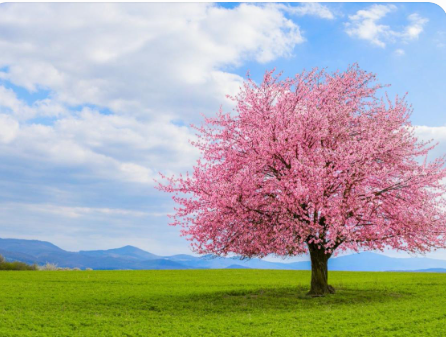

OUTPUT - Grayscale Image:


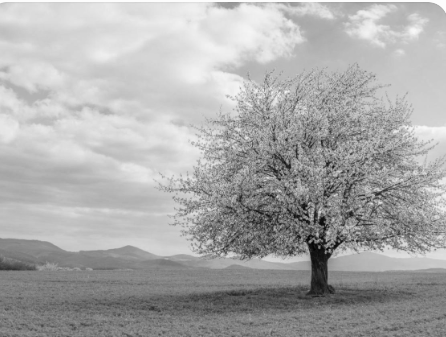

Grayscale image saved successfully.


In [ ]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload an image
uploaded = files.upload()

# Get the uploaded filename
filename = list(uploaded.keys())[0]

# Read the original image
img = cv2.imread(filename)

if img is None:
    print("Error: Unable to read the image.")
else:
    # Convert the image to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Display the images
    print("INPUT - Original Image:")
    cv2_imshow(img)

    print("OUTPUT - Grayscale Image:")
    cv2_imshow(gray_img)

    # Save the grayscale image
    cv2.imwrite('/content/gray_image.jpg', gray_img)

    print("Grayscale image saved successfully.")

Saving Screenshot 2026-10-24 142117.png to Screenshot 2026-10-24 142117.png
INPUT - Original Image:


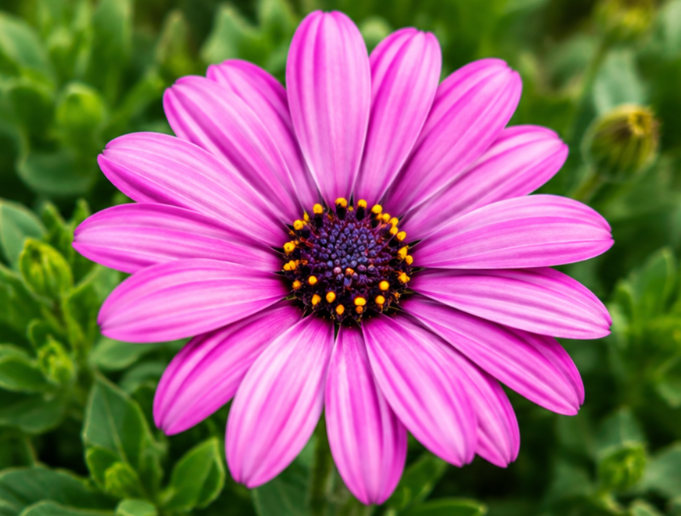

OUTPUT - Gaussian Blurred Image:


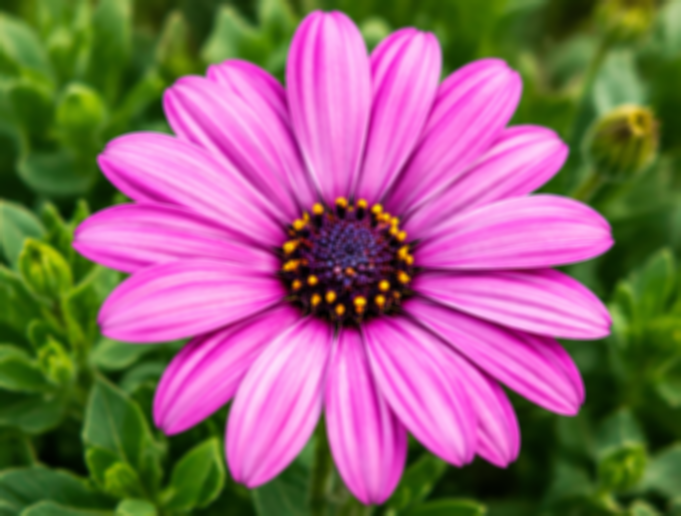

Blurred image saved successfully.


In [ ]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image
img = cv2.imread(filename)

if img is None:
    print("Error: Unable to read image.")
else:
    # Apply Gaussian Blur
    blurred_img = cv2.GaussianBlur(img, (5, 5), 10)

    # Display original image
    print("INPUT - Original Image:")
    cv2_imshow(img)

    # Display blurred image
    print("OUTPUT - Gaussian Blurred Image:")
    cv2_imshow(blurred_img)

    # Save output
    cv2.imwrite('/content/blurred_image.jpg', blurred_img)

    print("Blurred image saved successfully.")

Saving Screenshot 2026-10-24 142224.png to Screenshot 2026-10-24 142224.png
INPUT - Original Image:


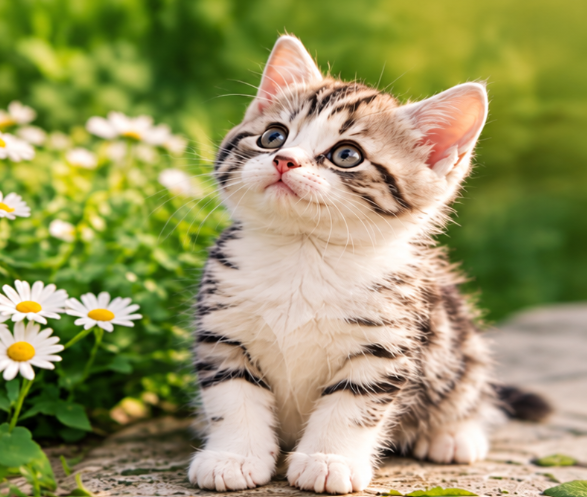

OUTPUT - Canny Edge Detection:


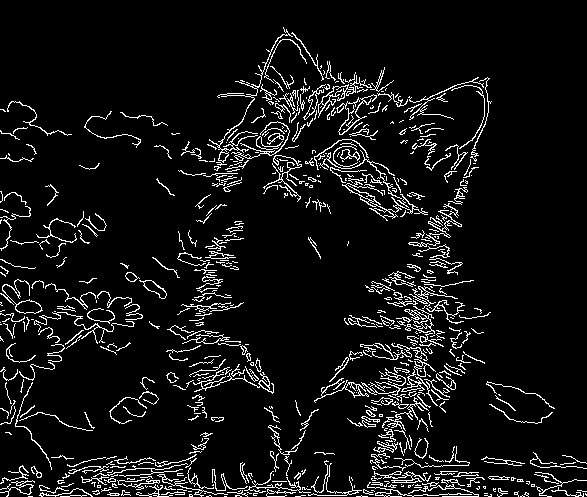

Edge image saved successfully.


In [ ]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image
img = cv2.imread(filename)

if img is None:
    print("Error: Unable to read image.")
else:
    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Canny edge detection
    edges = cv2.Canny(gray, 100, 200)

    # Display original image
    print("INPUT - Original Image:")
    cv2_imshow(img)

    # Display detected edges
    print("OUTPUT - Canny Edge Detection:")
    cv2_imshow(edges)

    # Save output
    cv2.imwrite('/content/Canny_Edges.jpg', edges)

    print("Edge image saved successfully.")

Saving Screenshot 2026-10-24 142117.png to Screenshot 2026-10-24 142117 (1).png
INPUT - Original Image:


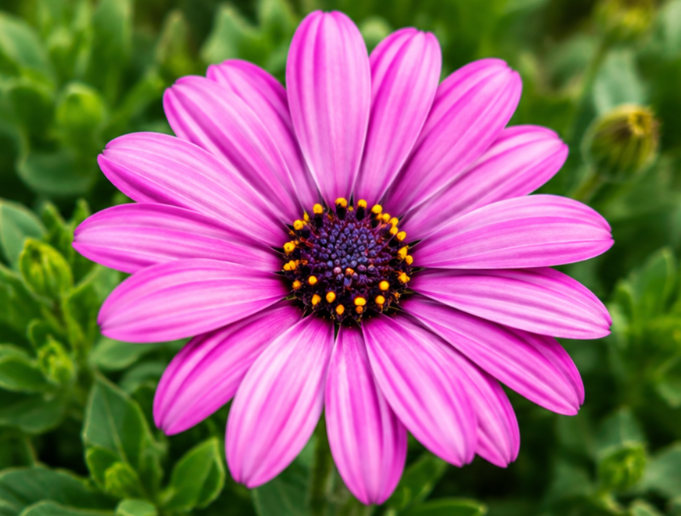

OUTPUT - Dilated Image:


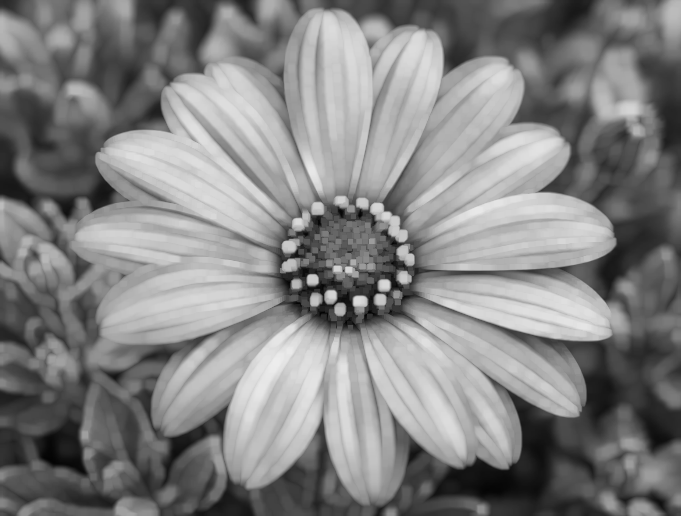

Dilated image saved successfully.


In [ ]:
#EX-4
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image
img = cv2.imread(filename)

if img is None:
    print("Error: Unable to read image.")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Create a 5x5 kernel
    kernel = np.ones((5, 5), np.uint8)

    # Apply dilation
    dilated = cv2.dilate(gray, kernel, iterations=1)

    # Display original image
    print("INPUT - Original Image:")
    cv2_imshow(img)

    # Display dilated image
    print("OUTPUT - Dilated Image:")
    cv2_imshow(dilated)

    # Save output
    cv2.imwrite('/content/Dilated_Image.jpg', dilated)

    print("Dilated image saved successfully.")

Saving Screenshot 2026-10-24 130925.png to Screenshot 2026-10-24 130925 (1).png
INPUT - Original Image:


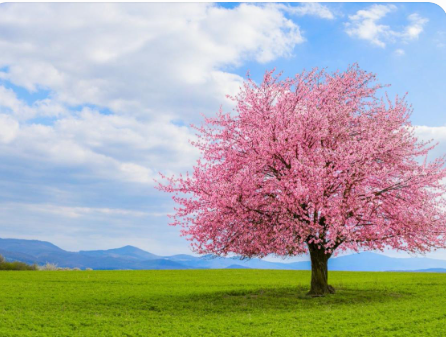

OUTPUT - Eroded Image:


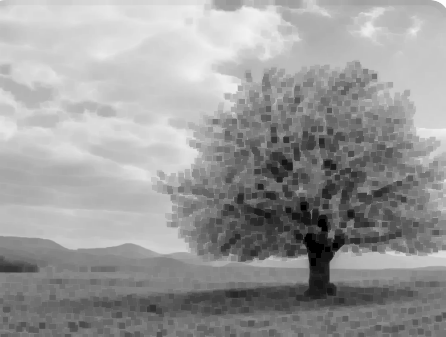

Eroded image saved successfully.


In [ ]:
#EX-5
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image in grayscale
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Unable to read image.")
else:
    # Create a 5x5 kernel
    kernel = np.ones((5, 5), np.uint8)

    # Apply erosion
    eroded_img = cv2.erode(img, kernel, iterations=1)

    # Display original colour image
    print("INPUT - Original Image:")
    cv2_imshow(cv2.imread(filename))

    # Display eroded grayscale image
    print("OUTPUT - Eroded Image:")
    cv2_imshow(eroded_img)

    # Save output
    cv2.imwrite('/content/Eroded_Image.jpg', eroded_img)

    print("Eroded image saved successfully.")

In [ ]:
#EX-6
!pip -q install imageio-ffmpeg

import cv2
import subprocess
import imageio_ffmpeg
from google.colab import files
from IPython.display import Video, display

# 1. Upload video
uploaded = files.upload()
if not uploaded:
    raise ValueError("Upload a video first.")

input_video = next(iter(uploaded.keys()))

# 2. Read video
cap = cv2.VideoCapture(input_video)
if not cap.isOpened():
    raise ValueError("Cannot open this video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 30

print("Original FPS:", fps)
print("Video dimensions:", width, "x", height)

# 3. Create a temporary video containing all frames
temp_video = "/content/temp_video.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(temp_video, fourcc, fps, (width, height))

count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    writer.write(frame)
    count += 1

cap.release()
writer.release()

if count == 0:
    raise ValueError("No frames were read from the uploaded video.")

print("Frames processed:", count)

# 4. Convert to browser-compatible H.264
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

def convert_video(output_path, output_fps):
    subprocess.run([
        ffmpeg, "-y", "-i", temp_video,
        "-an", "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2",
        "-r", str(output_fps),
        "-c:v", "libx264", "-pix_fmt", "yuv420p",
        "-movflags", "+faststart", output_path
    ], check=True, stdout=subprocess.DEVNULL,
       stderr=subprocess.PIPE)

# 5. Generate slow and fast motion
slow_path = "/content/slow_motion.mp4"
fast_path = "/content/fast_motion.mp4"

convert_video(slow_path, fps / 2)
convert_video(fast_path, fps * 2)

# 6. Display results
print("\nORIGINAL VIDEO:")
display(Video(input_video, embed=True))

print("\nSLOW MOTION VIDEO (half speed):")
display(Video(slow_path, embed=True))

print("\nFAST MOTION VIDEO (double speed):")
display(Video(fast_path, embed=True))

print("\nExperiment 6 completed successfully!")


Saving Screen Recording 2026-10-24 143006.mp4 to Screen Recording 2026-10-24 143006 (2).mp4
Original FPS: 30.0
Video dimensions: 380 x 628
Frames processed: 217

ORIGINAL VIDEO:



SLOW MOTION VIDEO (half speed):



FAST MOTION VIDEO (double speed):



Experiment 6 completed successfully!


In [ ]:
#EX-7

import cv2
import subprocess
import imageio_ffmpeg
from google.colab import files
from IPython.display import Video, display

# Step 1: Upload your video
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a video.")

input_video = next(iter(uploaded.keys()))
print("Uploaded video:", input_video)

# Step 2: Read the video
cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise ValueError("Unable to open the uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 30

cap.release()

# Step 3: Get FFmpeg
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

# Step 4: Create slow-motion video
slow_video = "/content/slow_motion.mp4"

subprocess.run([
    ffmpeg, "-y", "-i", input_video,
    "-vf", "setpts=2.0*PTS",
    "-an", "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    slow_video
], check=True)

# Step 5: Create fast-motion video
fast_video = "/content/fast_motion.mp4"

subprocess.run([
    ffmpeg, "-y", "-i", input_video,
    "-vf", "setpts=0.5*PTS",
    "-an", "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    fast_video
], check=True)

# Step 6: Display original video
print("ORIGINAL VIDEO:")
display(Video(input_video, embed=True))

# Step 7: Display slow-motion video
print("SLOW MOTION VIDEO:")
display(Video(slow_video, embed=True))

# Step 8: Display fast-motion video
print("FAST MOTION VIDEO:")
display(Video(fast_video, embed=True))

print("Experiment 7 completed successfully!")


Saving Screen Recording 2026-10-24 143006.mp4 to Screen Recording 2026-10-24 143006 (3).mp4
Uploaded video: Screen Recording 2026-10-24 143006 (3).mp4
ORIGINAL VIDEO:


SLOW MOTION VIDEO:


FAST MOTION VIDEO:


Experiment 7 completed successfully!


Saving Screenshot 2026-10-24 131254.png to Screenshot 2026-10-24 131254.png
Original Image:


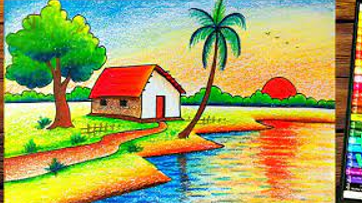

Larger Image:


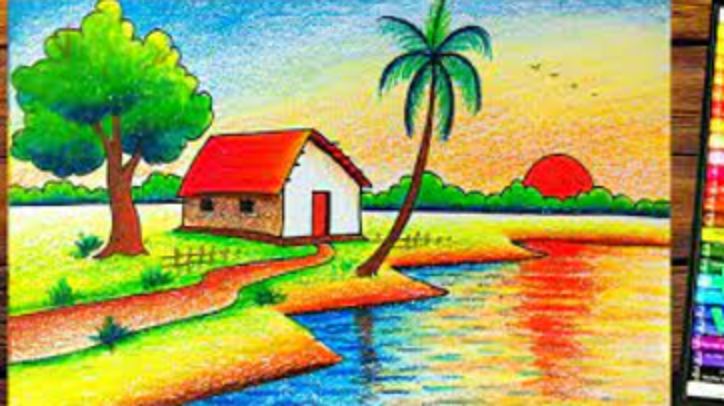

Smaller Image:


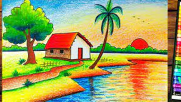

Experiment 8 completed successfully!
Original dimensions: 362 x 203
Larger dimensions: 724 x 406
Smaller dimensions: 181 x 102


In [ ]:
#EX-8

import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the image.")

# Step 3: Display the original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Increase the image size by 2 times
larger = cv2.resize(
    img, None, fx=2, fy=2,
    interpolation=cv2.INTER_LINEAR
)

# Step 5: Decrease the image size by half
smaller = cv2.resize(
    img, None, fx=0.5, fy=0.5,
    interpolation=cv2.INTER_AREA
)

# Step 6: Display the results
print("Larger Image:")
cv2_imshow(larger)

print("Smaller Image:")
cv2_imshow(smaller)

# Step 7: Save the output images
cv2.imwrite("/content/larger_image.jpg", larger)
cv2.imwrite("/content/smaller_image.jpg", smaller)

print("Experiment 8 completed successfully!")
print("Original dimensions:", img.shape[1], "x", img.shape[0])
print("Larger dimensions:", larger.shape[1], "x", larger.shape[0])
print("Smaller dimensions:", smaller.shape[1], "x", smaller.shape[0])


Saving Screenshot 2026-10-24 144043.png to Screenshot 2026-10-24 144043.png
Original Image:


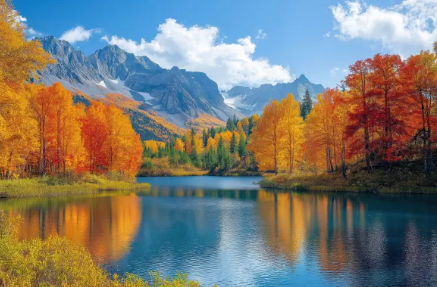

Image Rotated 90 Degrees Clockwise:


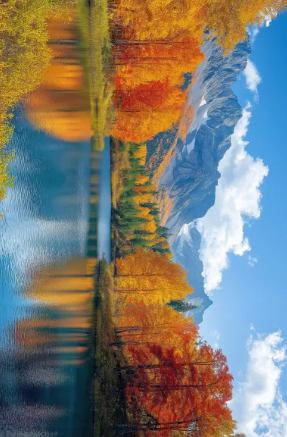

Image Rotated 90 Degrees Counter-Clockwise:


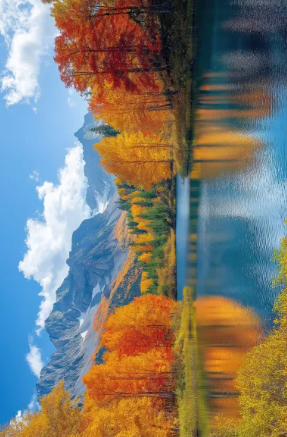

Experiment 9 completed successfully!


In [ ]:
#EX-9
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Rotate 90 degrees clockwise
clockwise = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

# Step 5: Rotate 90 degrees counter-clockwise
counter_clockwise = cv2.rotate(
    img, cv2.ROTATE_90_COUNTERCLOCKWISE
)

# Step 6: Display rotated images
print("Image Rotated 90 Degrees Clockwise:")
cv2_imshow(clockwise)

print("Image Rotated 90 Degrees Counter-Clockwise:")
cv2_imshow(counter_clockwise)

# Step 7: Save output images
cv2.imwrite("/content/clockwise.jpg", clockwise)
cv2.imwrite("/content/counter_clockwise.jpg", counter_clockwise)

print("Experiment 9 completed successfully!")


Saving Screenshot 2026-10-24 144033.png to Screenshot 2026-10-24 144033.png
Original Image:


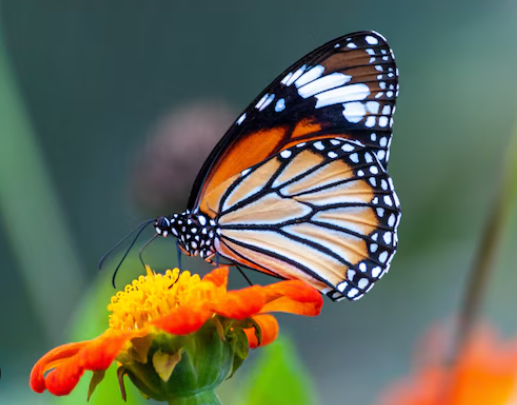

Image at Original Position:


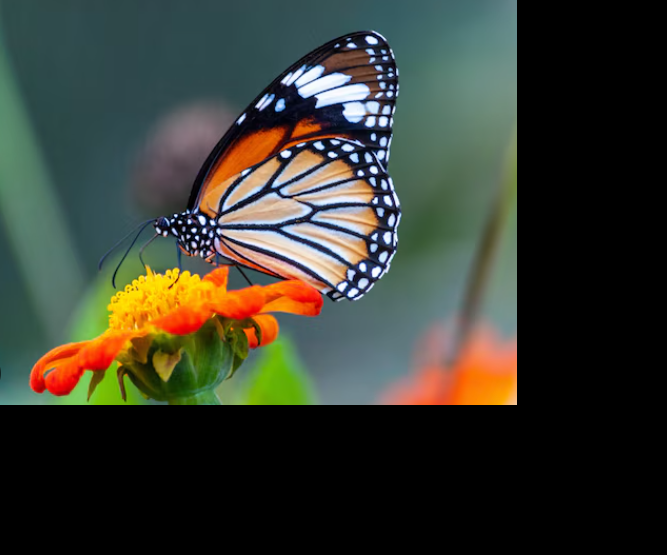

Image Moved 100 Pixels Right and Down:


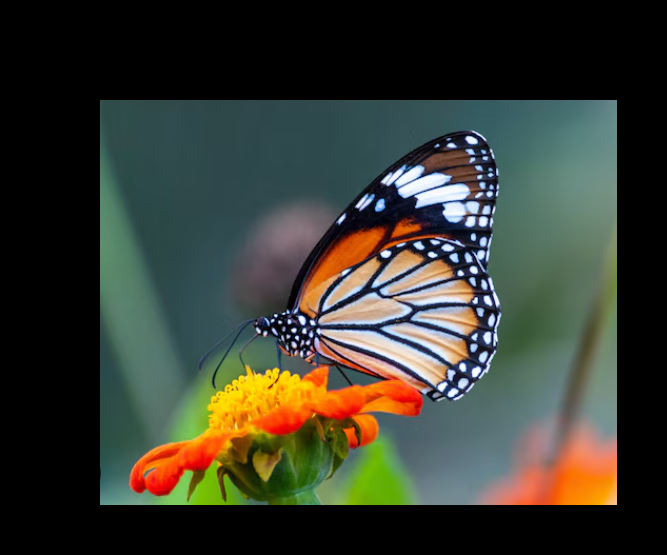

Experiment 10 completed successfully!


In [ ]:
#EX-10

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display the original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Get image dimensions
height, width = img.shape[:2]

# Step 5: Create a blank canvas
canvas = np.zeros((height + 150, width + 150, 3), dtype=np.uint8)

# Step 6: Place the image at its original position
canvas[0:height, 0:width] = img

print("Image at Original Position:")
cv2_imshow(canvas)

# Step 7: Move the image 100 pixels right and 100 pixels down
M = np.float32([[1, 0, 100],
                [0, 1, 100]])

moved_img = cv2.warpAffine(
    canvas, M, (canvas.shape[1], canvas.shape[0])
)

# Step 8: Display the moved image
print("Image Moved 100 Pixels Right and Down:")
cv2_imshow(moved_img)

# Step 9: Save the output
cv2.imwrite("/content/moved_image.jpg", moved_img)

print("Experiment 10 completed successfully!")


Saving Screenshot 2026-10-24 144054.png to Screenshot 2026-10-24 144054.png
Original Image:


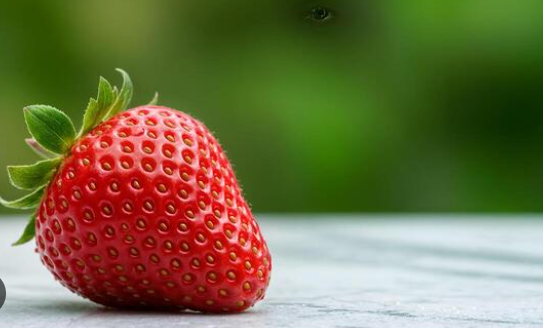

Affine Transformed Image:


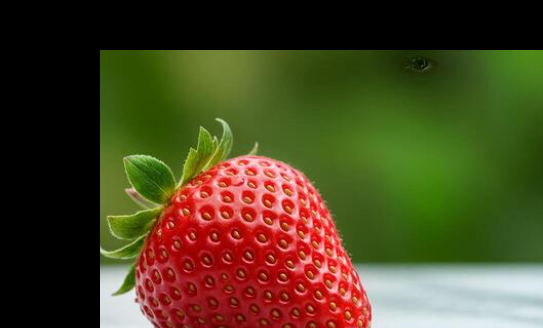

Experiment 11 completed successfully!


In [ ]:
#EX-11

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Get image dimensions
rows, cols = img.shape[:2]

# Step 5: Create affine transformation matrix
M = np.float32([
    [1, 0, 100],
    [0, 1, 50]
])

# Step 6: Apply affine transformation
affine_img = cv2.warpAffine(img, M, (cols, rows))

# Step 7: Display transformed image
print("Affine Transformed Image:")
cv2_imshow(affine_img)

# Step 8: Save the result
cv2.imwrite("/content/affine_transformed.jpg", affine_img)

print("Experiment 11 completed successfully!")


Saving Screenshot 2026-10-24 144336.png to Screenshot 2026-10-24 144336.png
Original Image:


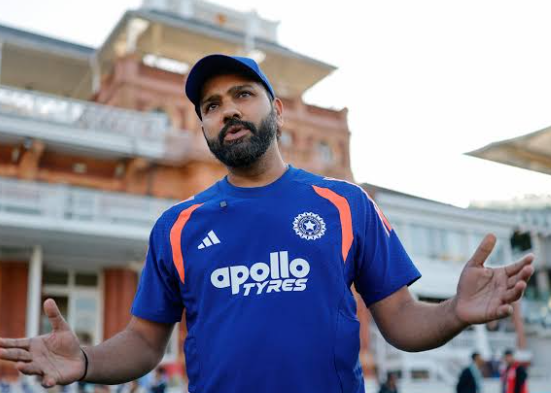

Perspective Transformed Image:


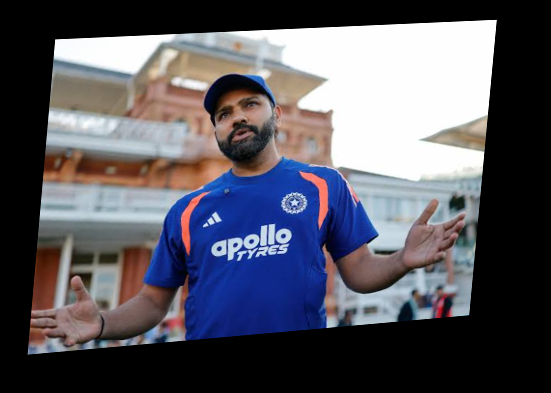

Experiment 12 completed successfully!


In [ ]:
#EX-12

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Get image dimensions
height, width = img.shape[:2]

# Step 5: Define four source points
source_points = np.float32([
    [0, 0],
    [width - 1, 0],
    [0, height - 1],
    [width - 1, height - 1]
])

# Step 6: Define four destination points
destination_points = np.float32([
    [width * 0.1, height * 0.1],
    [width * 0.9, height * 0.05],
    [width * 0.05, height * 0.9],
    [width * 0.85, height * 0.8]
])

# Step 7: Calculate perspective transformation matrix
M = cv2.getPerspectiveTransform(
    source_points, destination_points
)

# Step 8: Apply perspective transformation
perspective_img = cv2.warpPerspective(
    img, M, (width, height)
)

# Step 9: Display transformed image
print("Perspective Transformed Image:")
cv2_imshow(perspective_img)

# Step 10: Save output
cv2.imwrite(
    "/content/perspective_transformed.jpg",
    perspective_img
)

print("Experiment 12 completed successfully!")


In [ ]:

!pip -q install imageio-ffmpeg

import cv2
import numpy as np
import subprocess
import imageio_ffmpeg
import os
from google.colab import files
from IPython.display import Video, display

# Step 1: Upload a VIDEO file
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a video.")

input_video = next(iter(uploaded.keys()))

if not input_video.lower().endswith(
    (".mp4", ".avi", ".mov", ".mkv", ".webm")
):
    raise ValueError("Upload a video file, not a PNG or JPG image.")

# Step 2: Open the video
cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise ValueError("Unable to open the uploaded video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if fps <= 0:
    fps = 30

out_width = width - width % 2
out_height = height - height % 2

if out_width <= 0 or out_height <= 0:
    cap.release()
    raise ValueError("Invalid video dimensions.")

print("Video:", input_video)
print("FPS:", fps)
print("Dimensions:", width, "x", height)

# Step 3: Define perspective transformation points
src = np.float32([
    [0, 0],
    [width - 1, 0],
    [0, height - 1],
    [width - 1, height - 1]
])

dst = np.float32([
    [width * 0.15, height * 0.10],
    [width * 0.85, height * 0.10],
    [width * 0.05, height * 0.90],
    [width * 0.95, height * 0.90]
])

M = cv2.getPerspectiveTransform(src, dst)

# Step 4: Create temporary output video
temp_video = "/content/perspective_temp.mp4"

writer = cv2.VideoWriter(
    temp_video,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (out_width, out_height)
)

if not writer.isOpened():
    cap.release()
    raise ValueError("Unable to create output video.")

# Step 5: Transform every video frame
frames_processed = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    frame = cv2.resize(frame, (out_width, out_height))

    transformed = cv2.warpPerspective(
        frame,
        M,
        (out_width, out_height)
    )

    writer.write(transformed)
    frames_processed += 1

cap.release()
writer.release()

print("Frames processed:", frames_processed)

if frames_processed == 0:
    raise ValueError("No frames found. Please upload a valid video.")

# Step 6: Convert to browser-compatible MP4
output_video = "/content/perspective_transformed_video.mp4"
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

subprocess.run([
    ffmpeg, "-y",
    "-i", temp_video,
    "-c:v", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-an",
    output_video
], check=True, stdout=subprocess.DEVNULL,
   stderr=subprocess.PIPE)

if not os.path.exists(output_video):
    raise ValueError("Transformed video was not created.")

# Step 7: Display original video
print("\nORIGINAL VIDEO:")
display(Video(input_video, embed=True))

# Step 8: Display transformed video
print("\nPERSPECTIVE TRANSFORMED VIDEO:")
display(Video(output_video, embed=True))

print("\nExperiment 13 completed successfully!")


Saving Screen Recording 2026-10-24 143006.mp4 to Screen Recording 2026-10-24 143006 (4).mp4
Video: Screen Recording 2026-10-24 143006 (4).mp4
FPS: 30.0
Dimensions: 380 x 628
Frames processed: 217

ORIGINAL VIDEO:



PERSPECTIVE TRANSFORMED VIDEO:



Experiment 13 completed successfully!


Saving Screenshot 2026-10-24 144536.png to Screenshot 2026-10-24 144536 (3).png
Original Image:


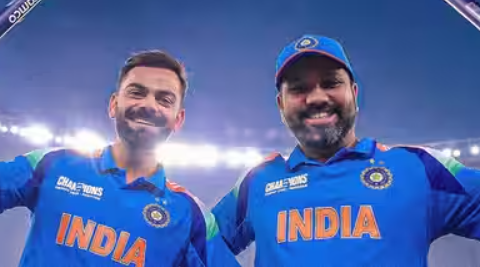

Homography Matrix:
[[ 6.88463560e-01  1.26466794e-01  4.80000000e+01]
 [-3.13689625e-02  8.67054910e-01  2.67000008e+01]
 [-2.62052282e-04  5.03350418e-04  1.00000000e+00]]
Homography Transformed Image:


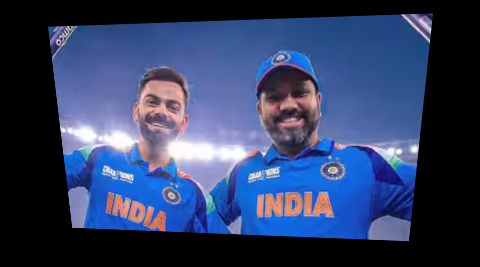

Experiment 14 completed successfully!


In [ ]:
#ex-14

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

height, width = img.shape[:2]

# Step 4: Define four source points
source_points = np.float32([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
])

# Step 5: Define four destination points
destination_points = np.float32([
    [width * 0.1, height * 0.1],
    [width * 0.9, height * 0.05],
    [width * 0.85, height * 0.9],
    [width * 0.15, height * 0.85]
])

# Step 6: Calculate homography matrix
H, status = cv2.findHomography(
    source_points, destination_points
)

if H is None:
    raise ValueError("Unable to calculate homography matrix.")

print("Homography Matrix:")
print(H)

# Step 7: Apply homography transformation
transformed_img = cv2.warpPerspective(
    img, H, (width, height)
)

# Step 8: Display transformed image
print("Homography Transformed Image:")
cv2_imshow(transformed_img)

# Step 9: Save output
cv2.imwrite("/content/homography_transformed.jpg", transformed_img)

print("Experiment 14 completed successfully!")


Saving Screenshot 2026-10-24 144508.png to Screenshot 2026-10-24 144508.png
Original Image:


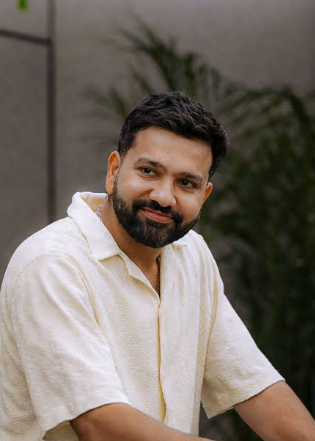

Homography Matrix calculated using DLT:
[[ 6.89217313e-01  5.01735454e-02  3.15000000e+01]
 [-7.90375183e-02  8.65770752e-01  4.40999985e+01]
 [-3.99754699e-04  3.04298218e-04  1.00000000e+00]]
DLT Transformed Image:


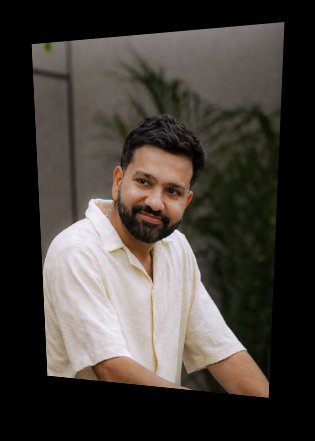

Experiment 15 completed successfully!


In [ ]:
#EX-15

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 2: Display original image
print("Original Image:")
cv2_imshow(img)

height, width = img.shape[:2]

# Step 3: Define corresponding source points
src = np.float32([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
])

# Step 4: Define corresponding destination points
dst = np.float32([
    [width * 0.1, height * 0.1],
    [width * 0.9, height * 0.05],
    [width * 0.85, height * 0.9],
    [width * 0.15, height * 0.85]
])

# Step 5: Calculate the homography using DLT
H, status = cv2.findHomography(src, dst, method=0)

if H is None:
    raise ValueError("DLT could not calculate the transformation matrix.")

print("Homography Matrix calculated using DLT:")
print(H)

# Step 6: Apply the transformation
transformed = cv2.warpPerspective(img, H, (width, height))

# Step 7: Display transformed image
print("DLT Transformed Image:")
cv2_imshow(transformed)

# Step 8: Save the output
cv2.imwrite("/content/dlt_transformed.jpg", transformed)

print("Experiment 15 completed successfully!")


Saving Screenshot 2026-10-24 144536.png to Screenshot 2026-10-24 144536.png
Original Image:


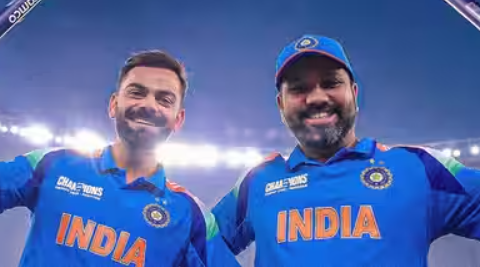

Canny Edge Detection:


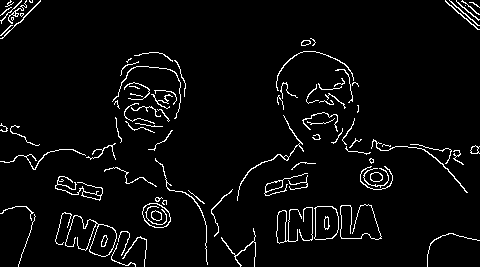

Experiment 16 completed successfully!


In [ ]:
#EX-16
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 5: Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 6: Apply Canny edge detection
edges = cv2.Canny(blur, 100, 200)

# Step 7: Display the edge-detected image
print("Canny Edge Detection:")
cv2_imshow(edges)

# Step 8: Save the output
cv2.imwrite("/content/canny_edges.jpg", edges)

print("Experiment 16 completed successfully!")


Saving dog.jpg.jpg to dog.jpg.jpg
Original Image:


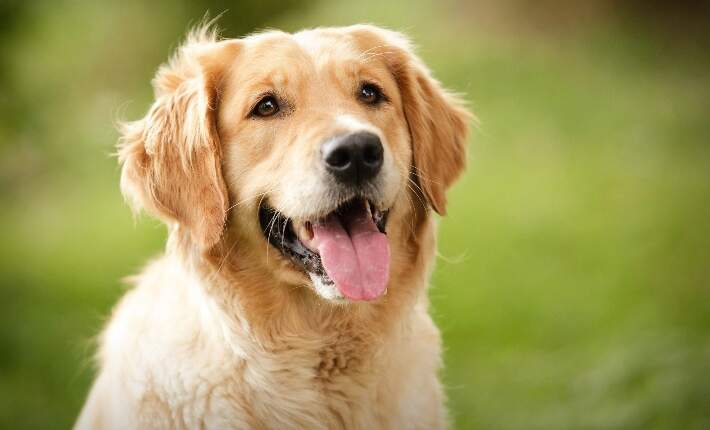

Sobel X Edge Detection:


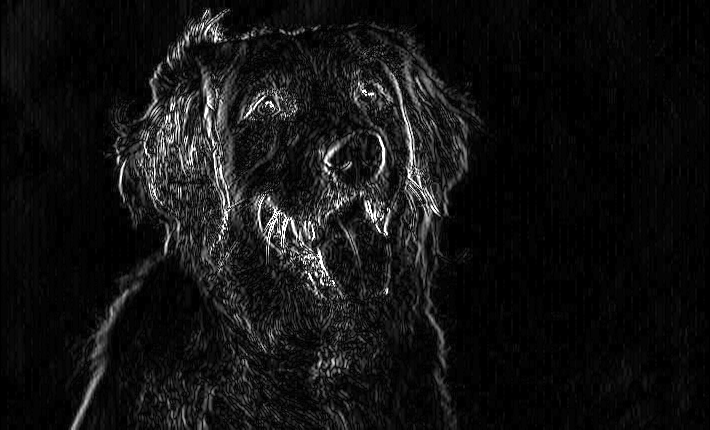

Experiment 17 completed successfully!


In [ ]:
#EX-17
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Step 1: Upload an image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

# Step 2: Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

# Step 3: Display original image
print("Original Image:")
cv2_imshow(img)

# Step 4: Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 5: Apply Sobel X operator
sobel_x = cv2.Sobel(
    gray,
    cv2.CV_64F,
    dx=1,
    dy=0,
    ksize=3
)

# Step 6: Convert result to 8-bit image
sobel_x = cv2.convertScaleAbs(sobel_x)

# Step 7: Display result
print("Sobel X Edge Detection:")
cv2_imshow(sobel_x)

# Step 8: Save output
cv2.imwrite("/content/sobel_x.jpg", sobel_x)

print("Experiment 17 completed successfully!")


Saving Screenshot 2026-10-24 144336.png to Screenshot 2026-10-24 144336.png
Original Image:


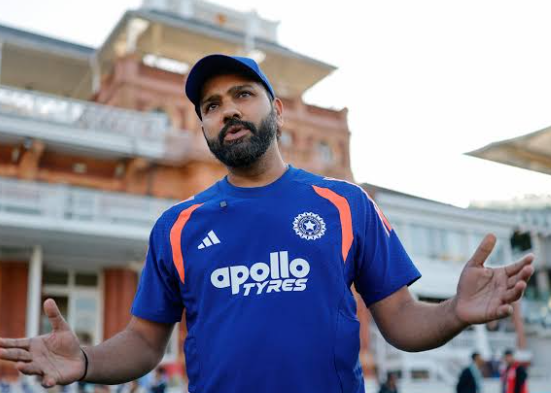

Sobel Y Edge Detection:


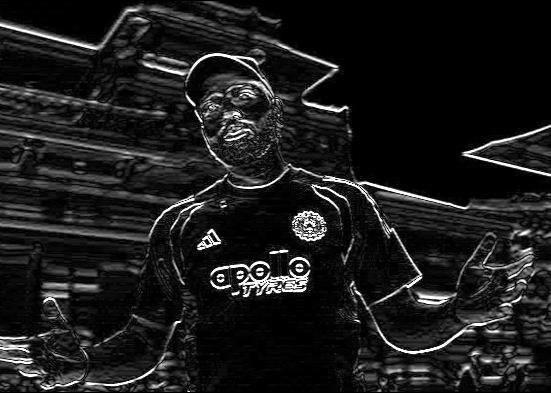

Sobel Y output saved successfully.


In [ ]:
#EX-18
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Convert image to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply Sobel Y operator
        sobel_y = cv2.Sobel(
            gray, cv2.CV_64F,
            dx=0, dy=1, ksize=3
        )

        # Convert result to 8-bit image
        sobel_y = cv2.convertScaleAbs(sobel_y)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Sobel Y Edge Detection:")
        cv2_imshow(sobel_y)

        # Save output
        cv2.imwrite("sobel_y_output.jpg", sobel_y)

        print("Sobel Y output saved successfully.")


Saving IMG(4).jpeg to IMG(4).jpeg
Original Image:


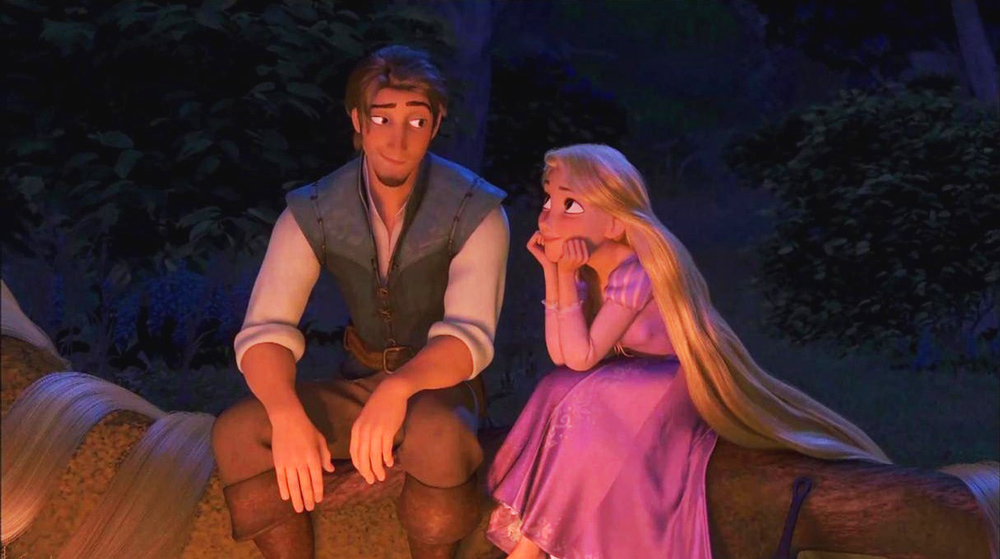

Sobel XY Edge Detection:


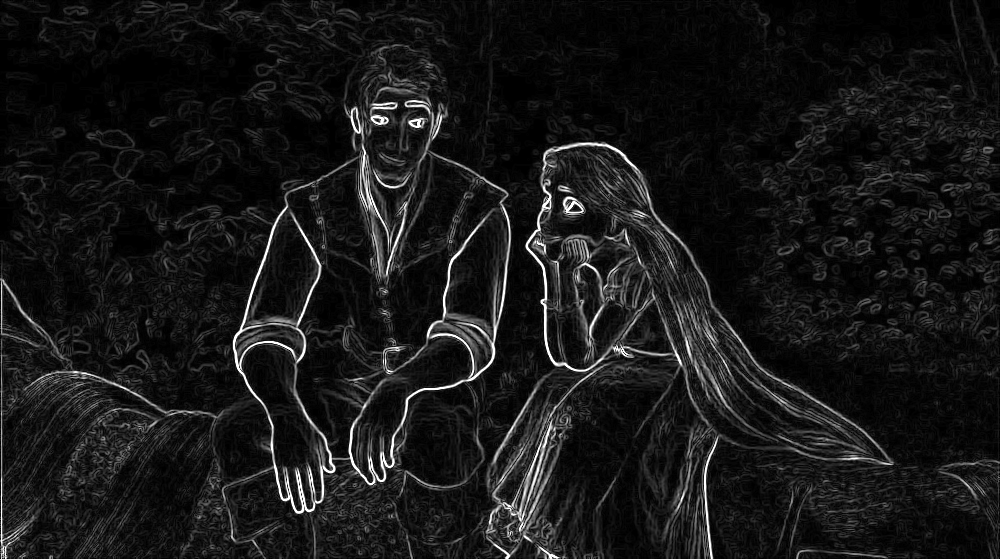

Sobel XY output saved successfully.


In [ ]:
#EX-19
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Convert image to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply Sobel X and Sobel Y
        sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

        # Combine X and Y gradients
        sobel_xy = cv2.magnitude(
            sobel_x.astype(np.float32),
            sobel_y.astype(np.float32)
        )

        # Convert to 8-bit image
        sobel_xy = cv2.convertScaleAbs(sobel_xy)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Sobel XY Edge Detection:")
        cv2_imshow(sobel_xy)

        # Save output
        cv2.imwrite("sobel_xy_output.jpg", sobel_xy)

        print("Sobel XY output saved successfully.")


Saving IMG.png to IMG.png
Original Image:


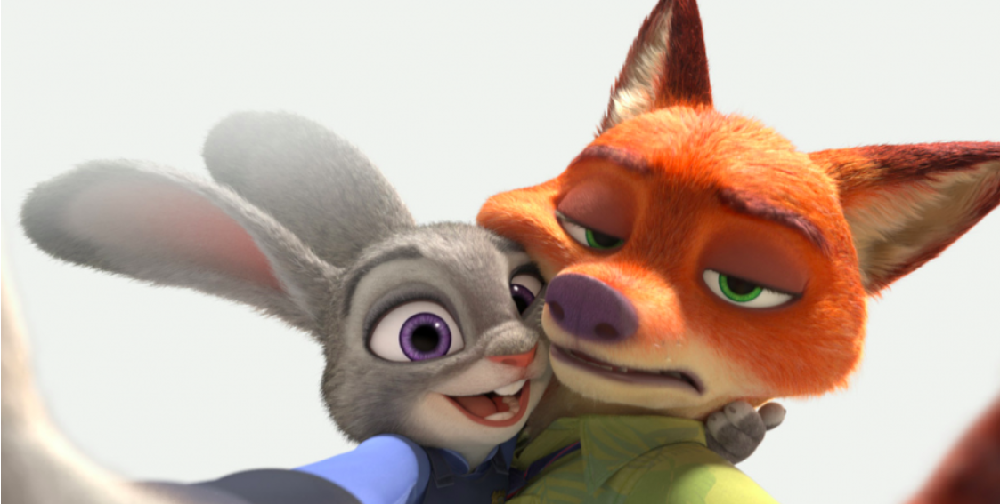

Laplacian Sharpened Image:


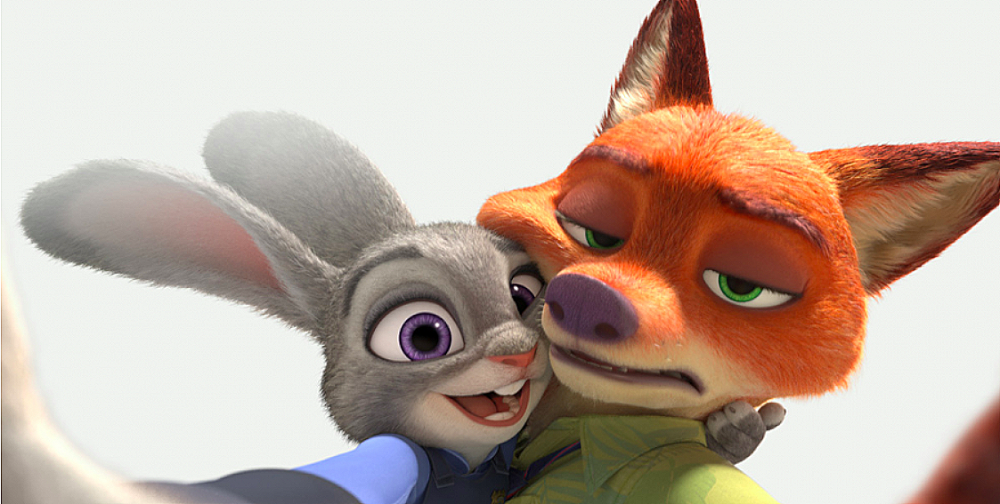

Output saved successfully.


In [ ]:
#EX-20
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Laplacian mask with negative center coefficient
        laplacian_kernel = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)

        # Apply Laplacian filter
        laplacian = cv2.filter2D(
            img, cv2.CV_32F, laplacian_kernel
        )

        # Sharpen image
        sharpened = img.astype(np.float32) - laplacian

        # Convert to 8-bit image
        sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Laplacian Sharpened Image:")
        cv2_imshow(sharpened)

        # Save output
        cv2.imwrite("laplacian_sharpened.jpg", sharpened)

        print("Output saved successfully.")


Saving IMG(1).jpeg to IMG(1).jpeg
Original Image:


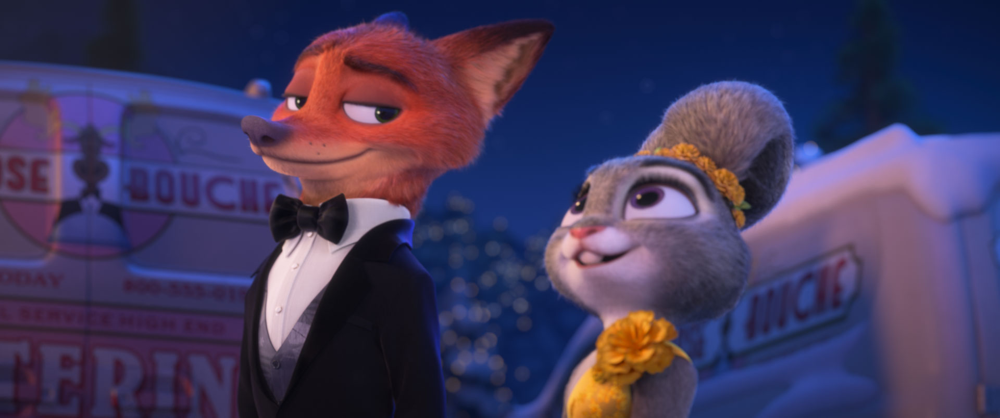

Sharpened Image:


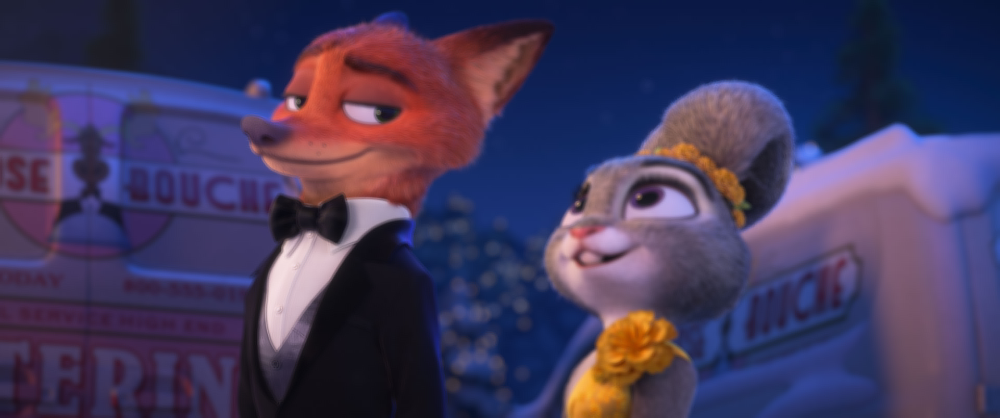

Output saved successfully.


In [ ]:
#EX-21
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Laplacian mask using diagonal neighbors
        laplacian_kernel = np.array([
            [-1,  0, -1],
            [ 0,  4,  0],
            [-1,  0, -1]
        ], dtype=np.float32)

        # Apply Laplacian filter
        laplacian = cv2.filter2D(
            img, cv2.CV_32F, laplacian_kernel
        )

        # Sharpen image
        sharpened = img.astype(np.float32) - laplacian

        # Convert to 8-bit image
        sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Sharpened Image:")
        cv2_imshow(sharpened)

        # Save output
        cv2.imwrite("diagonal_laplacian_sharpened.jpg", sharpened)

        print("Output saved successfully.")


Saving Screenshot 2026-10-24 130925.png to Screenshot 2026-10-24 130925.png
Original Image:


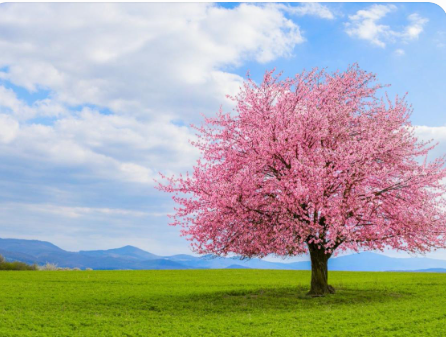

Sharpened Image:


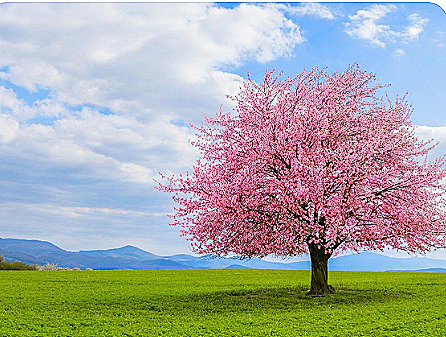

Output saved successfully.


In [ ]:
# EX-22
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Laplacian mask with positive center coefficient
        laplacian_kernel = np.array([
            [ 0, -1,  0],
            [-1,  4, -1],
            [ 0, -1,  0]
        ], dtype=np.float32)

        # Apply Laplacian filter
        laplacian = cv2.filter2D(
            img, cv2.CV_32F, laplacian_kernel
        )

        # Sharpen image
        sharpened = img.astype(np.float32) + laplacian

        # Convert to 8-bit image
        sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Sharpened Image:")
        cv2_imshow(sharpened)

        # Save output
        cv2.imwrite("positive_laplacian_sharpened.jpg", sharpened)

        print("Output saved successfully.")


Saving Screenshot 2026-10-27 141640.png to Screenshot 2026-10-27 141640.png
Original Image:


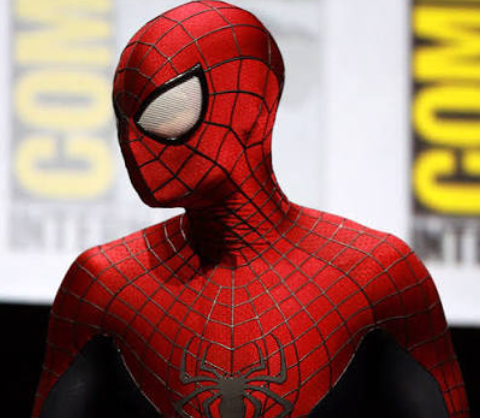

Blurred Image:


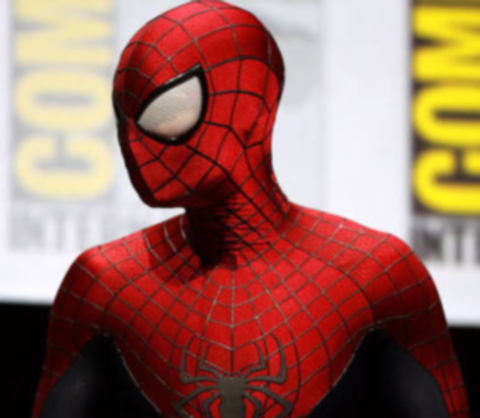

Unsharp Masked Image:


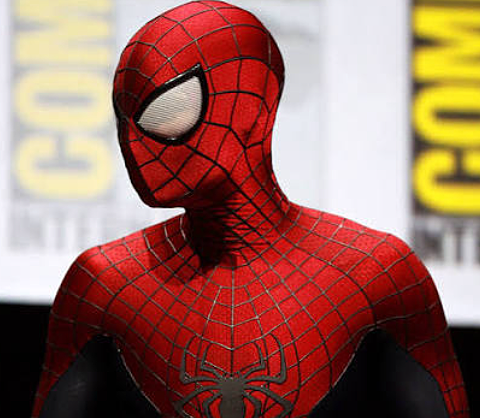

Output saved successfully.


In [ ]:

# EX-23: Image Sharpening Using Unsharp Masking

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Apply Gaussian blur
        blurred = cv2.GaussianBlur(img, (5, 5), 0)

        # Apply unsharp masking
        sharpened = cv2.addWeighted(
            img, 1.5,
            blurred, -0.5,
            0
        )

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Blurred Image:")
        cv2_imshow(blurred)

        print("Unsharp Masked Image:")
        cv2_imshow(sharpened)

        # Save output
        cv2.imwrite("unsharp_masking_output.jpg", sharpened)

        print("Output saved successfully.")


Saving Screenshot 2026-10-27 141813.png to Screenshot 2026-10-27 141813.png
Original Image:


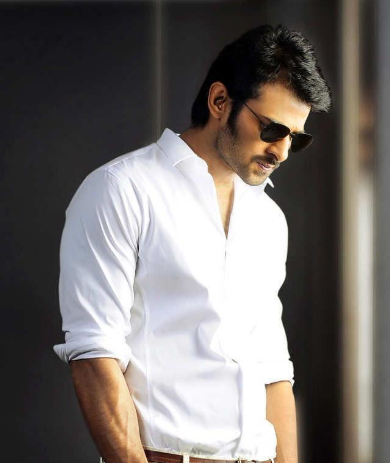

Blurred Image:


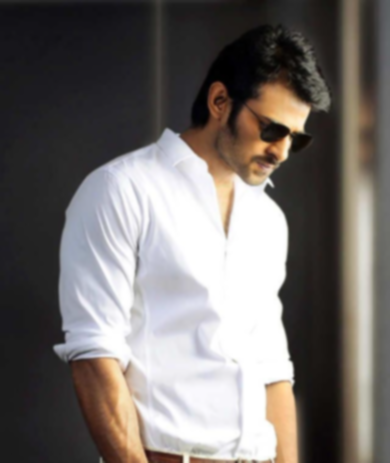

High Boost Filtered Image:


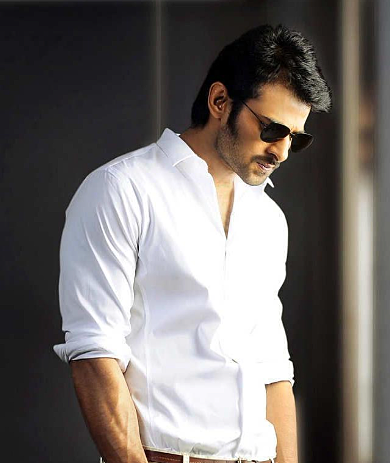

Output saved successfully.


In [ ]:

# EX-24: Image Sharpening Using High Boost Filtering

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Apply Gaussian blur
        blurred = cv2.GaussianBlur(img, (5, 5), 0)

        # High boost factor
        A = 1.5

        # Apply high boost filtering
        high_boost = cv2.addWeighted(
            img, A,
            blurred, -(A - 1),
            0
        )

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Blurred Image:")
        cv2_imshow(blurred)

        print("High Boost Filtered Image:")
        cv2_imshow(high_boost)

        # Save output
        cv2.imwrite("high_boost_output.jpg", high_boost)

        print("Output saved successfully.")


Saving IMG(3).jpeg to IMG(3).jpeg
Original Image:


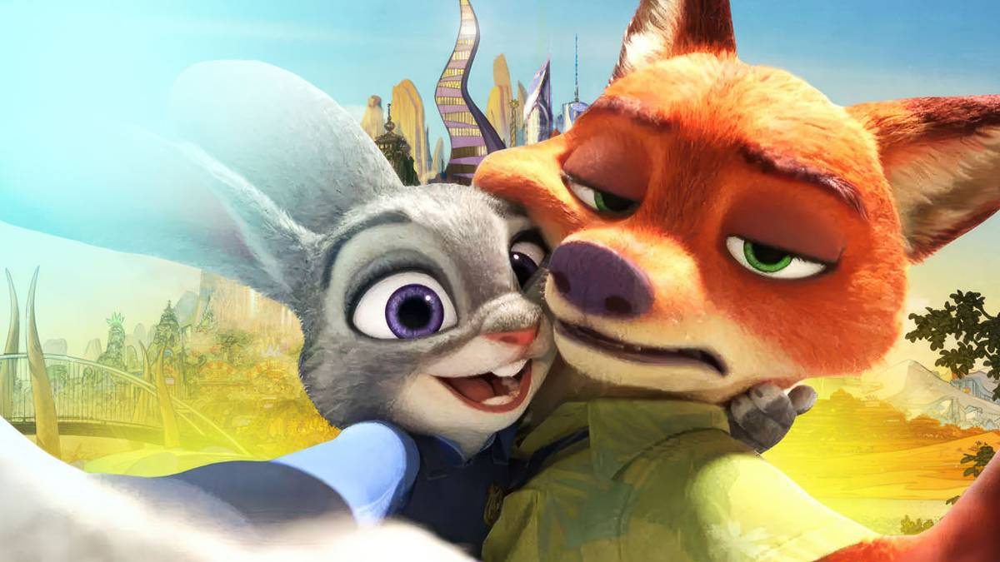

Gradient Masked Image:


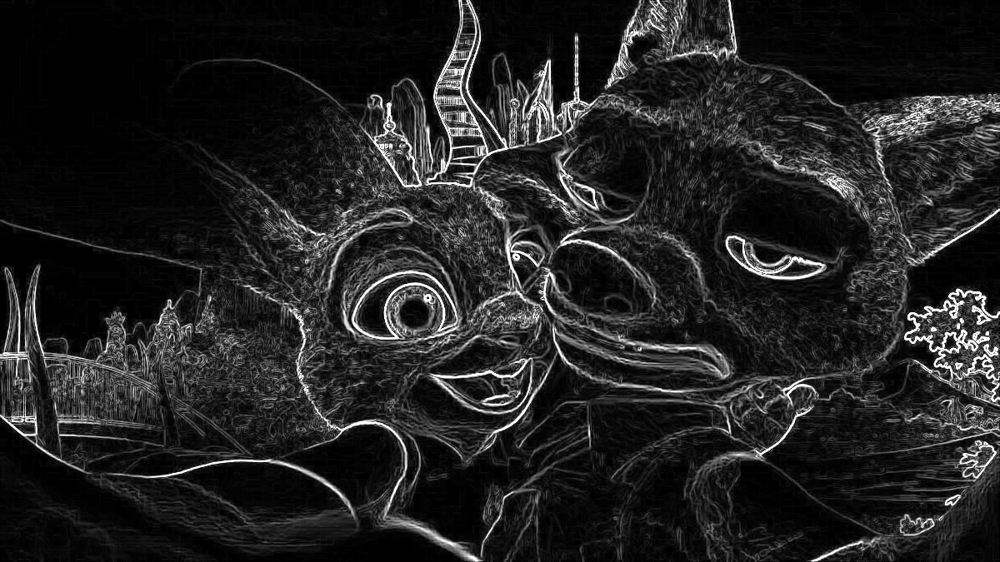

Output saved successfully.


In [ ]:

# EX-25: Gradient Masking

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Convert image to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply Sobel X gradient
        sobel_x = cv2.Sobel(
            gray, cv2.CV_64F, 1, 0, ksize=3
        )

        # Apply Sobel Y gradient
        sobel_y = cv2.Sobel(
            gray, cv2.CV_64F, 0, 1, ksize=3
        )

        # Calculate gradient magnitude
        gradient = cv2.magnitude(
            sobel_x.astype(np.float32),
            sobel_y.astype(np.float32)
        )

        # Convert to 8-bit image
        gradient = cv2.convertScaleAbs(gradient)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Gradient Masked Image:")
        cv2_imshow(gradient)

        # Save output
        cv2.imwrite("gradient_masking_output.jpg", gradient)

        print("Output saved successfully.")


Saving Screenshot 2026-11-20 115658.png to Screenshot 2026-11-20 115658 (1).png
Saving Screenshot 2026-11-20 115727.png to Screenshot 2026-11-20 115727.png
Original Image:


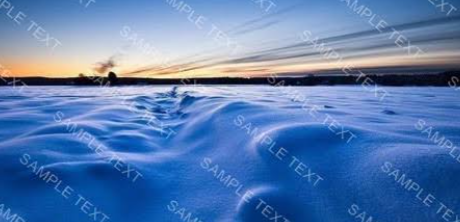

Watermarked Image:


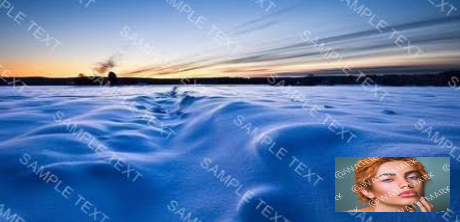

Watermarked image saved successfully.


In [2]:

# EX-26: Adding Watermark to an Image

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload two images:
# 1. Original image
# 2. Watermark image or logo
uploaded = files.upload()

if len(uploaded) < 2:
    print("Please upload two images: original image and watermark image.")
else:
    filenames = list(uploaded.keys())

    # Read original image
    original = cv2.imread(filenames[0])

    # Read watermark image with transparency support
    watermark = cv2.imread(filenames[1], cv2.IMREAD_UNCHANGED)

    if original is None or watermark is None:
        print("Invalid image file.")
    else:
        # Resize watermark
        h, w = original.shape[:2]
        watermark = cv2.resize(watermark, (w // 4, h // 4))

        # Convert watermark to 3 channels if needed
        if len(watermark.shape) == 2:
            watermark = cv2.cvtColor(
                watermark, cv2.COLOR_GRAY2BGR
            )

        # Set watermark position (bottom-right corner)
        wh, ww = watermark.shape[:2]
        x = w - ww - 10
        y = h - wh - 10

        # Create output image
        result = original.copy()

        # Blend watermark with original image
        if watermark.shape[2] == 4:
            # Use PNG transparency channel
            alpha = watermark[:, :, 3] / 255.0

            for c in range(3):
                result[y:y+wh, x:x+ww, c] = (
                    alpha * watermark[:, :, c] +
                    (1 - alpha) * result[y:y+wh, x:x+ww, c]
                )
        else:
            # Use fixed transparency for normal images
            roi = result[y:y+wh, x:x+ww]
            result[y:y+wh, x:x+ww] = cv2.addWeighted(
                roi, 0.7, watermark, 0.3, 0
            )

        # Display images
        print("Original Image:")
        cv2_imshow(original)

        print("Watermarked Image:")
        cv2_imshow(result)

        # Save output
        cv2.imwrite("watermarked_image.jpg", result)

        print("Watermarked image saved successfully.")


Saving Screenshot 2026-11-20 115850.png to Screenshot 2026-11-20 115850.png
Saving Screenshot 2026-11-20 115853.png to Screenshot 2026-11-20 115853.png
Source Image:


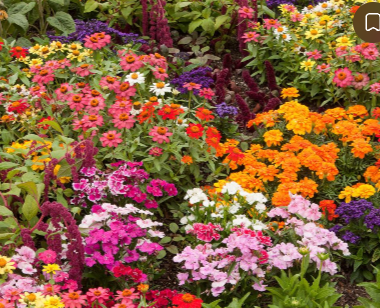

Cropped Image:


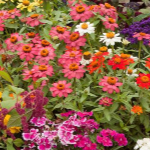

Destination Image:


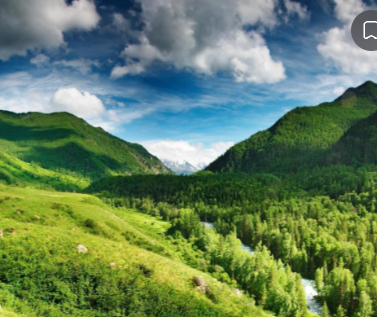

Final Image After Copy and Paste:


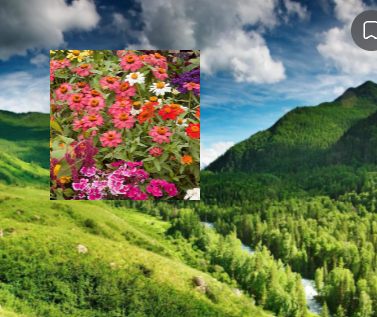

Output saved successfully.


In [4]:

# EX-27: Cropping, Copying and Pasting an Image

import cv2
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload two images
# 1. Source image
# 2. Destination image
uploaded = files.upload()

if len(uploaded) < 2:
    print("Please upload two images.")
else:
    filenames = list(uploaded.keys())

    # Read both images
    source = cv2.imread(filenames[0])
    destination = cv2.imread(filenames[1])

    if source is None or destination is None:
        print("Invalid image file.")
    else:
        # Crop a region from source image
        cropped = source[50:200, 50:200]

        # Get cropped image dimensions
        h, w = cropped.shape[:2]

        # Check destination size
        if h > destination.shape[0] or w > destination.shape[1]:
            print("Cropped region is larger than destination image.")
        else:
            # Copy cropped region into destination image
            result = destination.copy()
            result[50:50+h, 50:50+w] = cropped

            # Display images
            print("Source Image:")
            cv2_imshow(source)

            print("Cropped Image:")
            cv2_imshow(cropped)

            print("Destination Image:")
            cv2_imshow(destination)

            print("Final Image After Copy and Paste:")
            cv2_imshow(result)

            # Save output
            cv2.imwrite("cropped_pasted_image.jpg", result)

            print("Output saved successfully.")


Saving Screenshot 2026-11-20 115941.png to Screenshot 2026-11-20 115941.png
Original Image:


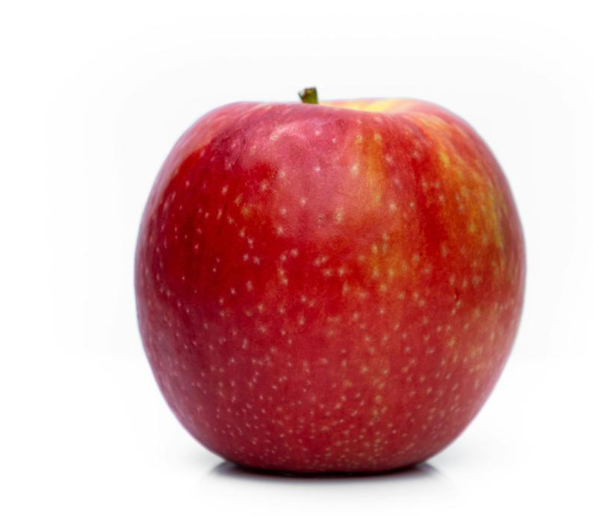

Boundary Detected Image:


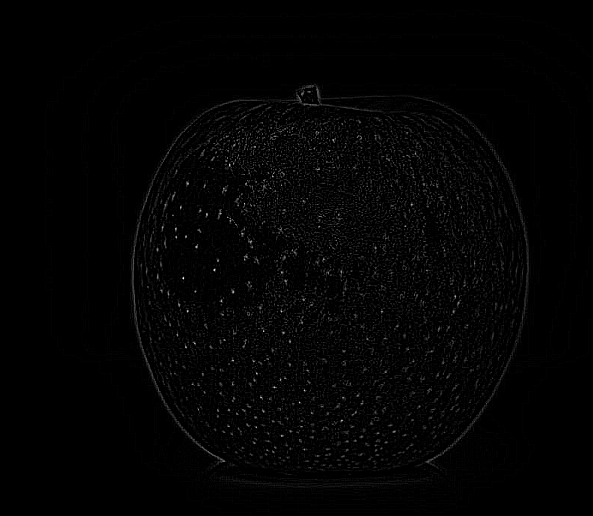

Output saved successfully.


In [5]:

# EX-28: Boundary Detection Using Convolution Kernel

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image
    img = cv2.imread(filename)

    if img is None:
        print("Invalid image file.")
    else:
        # Convert image to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Define boundary detection kernel
        kernel = np.array([
            [-1, -1, -1],
            [-1,  8, -1],
            [-1, -1, -1]
        ])

        # Apply convolution kernel
        boundary = cv2.filter2D(
            gray, -1, kernel
        )

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Boundary Detected Image:")
        cv2_imshow(boundary)

        # Save output
        cv2.imwrite("boundary_detection_output.jpg", boundary)

        print("Output saved successfully.")


Saving Screenshot 2026-11-20 120023.png to Screenshot 2026-11-20 120023.png
Original Image:


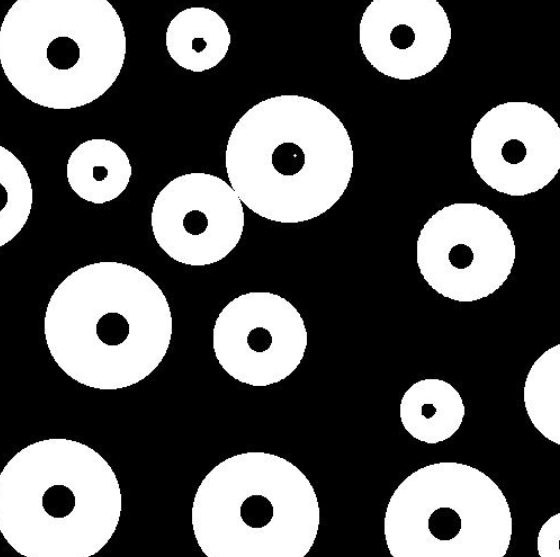

Eroded Image:


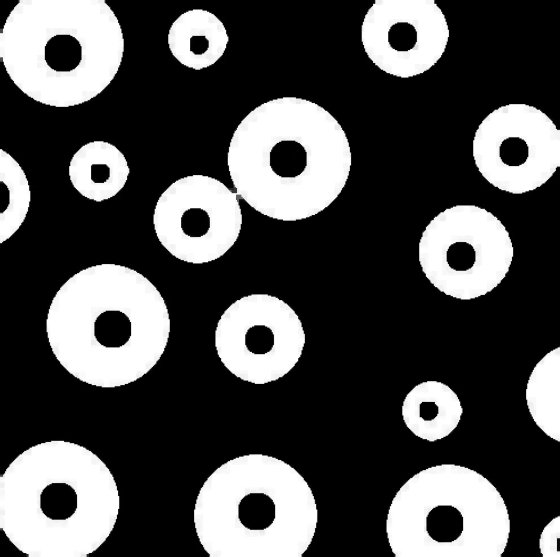

Output saved successfully.


In [6]:

# EX-29: Morphological Operation Using Erosion

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image in grayscale
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print("Invalid image file.")
    else:
        # Create kernel
        kernel = np.ones((5, 5), np.uint8)

        # Apply erosion
        erosion = cv2.erode(img, kernel, iterations=1)

        # Display images
        print("Original Image:")
        cv2_imshow(img)

        print("Eroded Image:")
        cv2_imshow(erosion)

        # Save output
        cv2.imwrite("erosion_output.jpg", erosion)

        print("Output saved successfully.")


Saving Screenshot 2026-11-20 120137.png to Screenshot 2026-11-20 120137.png
Original Image:


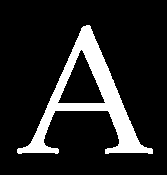

Dilated Image:


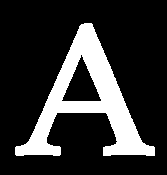

Output saved successfully.


In [7]:

# EX-30: Morphological Operation Using Dilation

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload image
uploaded = files.upload()

if not uploaded:
    print("Please upload an image.")
else:
    filename = next(iter(uploaded))

    # Read image in grayscale
    img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print("Invalid image file.")
    else:
        # Convert image into binary format
        _, binary = cv2.threshold(
            img, 127, 255, cv2.THRESH_BINARY
        )

        # Create kernel
        kernel = np.ones((5, 5), np.uint8)

        # Apply dilation
        dilation = cv2.dilate(
            binary, kernel, iterations=1
        )

        # Display images
        print("Original Image:")
        cv2_imshow(binary)

        print("Dilated Image:")
        cv2_imshow(dilation)

        # Save output
        cv2.imwrite("dilation_output.jpg", dilation)

        print("Output saved successfully.")
